In [1]:

import time

import matplotlib.pyplot as plt
import numpy as np


def attention(query, key, value):
    attention_scores = query @ key.transpose(0, 2, 1) / np.sqrt(query.shape[-1])

    attention_scores = attention_scores - np.max(attention_scores, axis=-1, keepdims=True)

    attention_weights = np.exp(attention_scores)
    attention_weights = attention_weights / np.sum(attention_weights, axis=-1, keepdims=True)

    return attention_weights @ value


def benchmark_attention(sequence_lengths, model_dimension, number_of_heads):

    execution_times_ms = []
    attention_memory_mb = []

    head_dimension = model_dimension // number_of_heads

    for sequence_length in sequence_lengths:

        # Generate Q, K, V
        query = np.random.randn(number_of_heads, sequence_length, head_dimension).astype(np.float32)
        key = np.random.randn(number_of_heads, sequence_length, head_dimension).astype(np.float32)
        value = np.random.randn(number_of_heads, sequence_length, head_dimension).astype(np.float32)

        # Measure execution time
        start_time = time.perf_counter()
        attention_output = attention(query, key, value)
        end_time = time.perf_counter()

        elapsed_time_ms = (end_time - start_time) * 1000
        execution_times_ms.append(elapsed_time_ms)

        # Calculate attention matrix memory in MB
        sequence_attention_memory_mb = number_of_heads * sequence_length * sequence_length * 4 / (1024 ** 2)
        attention_memory_mb.append(sequence_attention_memory_mb)

        print(f"Sequence Length: {sequence_length}")
        print(f"Execution Time: {elapsed_time_ms:.4f} ms")
        print(f"Memory: {sequence_attention_memory_mb:.4f} MB")
        print("------------------------")

    # Plot execution time
    plt.plot(sequence_lengths, execution_times_ms, marker='o')
    plt.xlabel("Sequence Length")
    plt.ylabel("Execution Time (ms)")
    plt.title("Attention Execution Time")
    plt.grid()
    plt.show()

    return execution_times_ms, attention_memory_mb

Sequence Length: 32
Execution Time: 0.3864 ms
Memory: 0.0156 MB
------------------------
Sequence Length: 64
Execution Time: 0.1885 ms
Memory: 0.0625 MB
------------------------
Sequence Length: 128
Execution Time: 0.7070 ms
Memory: 0.2500 MB
------------------------
Sequence Length: 256
Execution Time: 2.6971 ms
Memory: 1.0000 MB
------------------------
Sequence Length: 512
Execution Time: 13.1264 ms
Memory: 4.0000 MB
------------------------


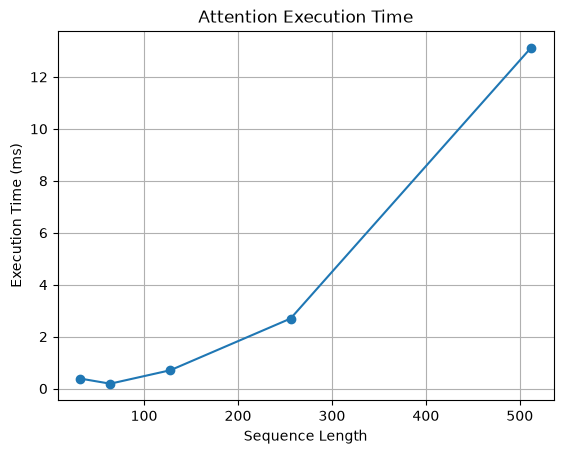

In [2]:
sample_sequence_lengths = [32, 64, 128, 256, 512]

execution_times_ms, attention_memory_mb = benchmark_attention(
    sample_sequence_lengths,
    model_dimension=64,
    number_of_heads=4
)